<a href="https://colab.research.google.com/github/samarthpendse0-lab/Time-Series-Data-Weather-Forecast-Using-Logistic-Regression/blob/main/pds_pbl3ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving weather.csv to weather.csv


First 5 rows:
     Date  Temperature  Humidity  Pressure  Wind_Speed  Cloud_Cover  \
0  01 Jun           30        62      1012          10           35   
1  02 Jun           31        60      1011          12           30   
2  03 Jun           29        68      1009          15           55   
3  04 Jun           27        76      1007          18           78   
4  05 Jun           26        82      1005          20           90   

   Rain_Tomorrow  
0              0  
1              0  
2              0  
3              1  
4              1  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Date           20 non-null     object
 1   Temperature    20 non-null     int64 
 2   Humidity       20 non-null     int64 
 3   Pressure       20 non-null     int64 
 4   Wind_Speed     20 non-null     int64 
 5   Cloud_Cover    

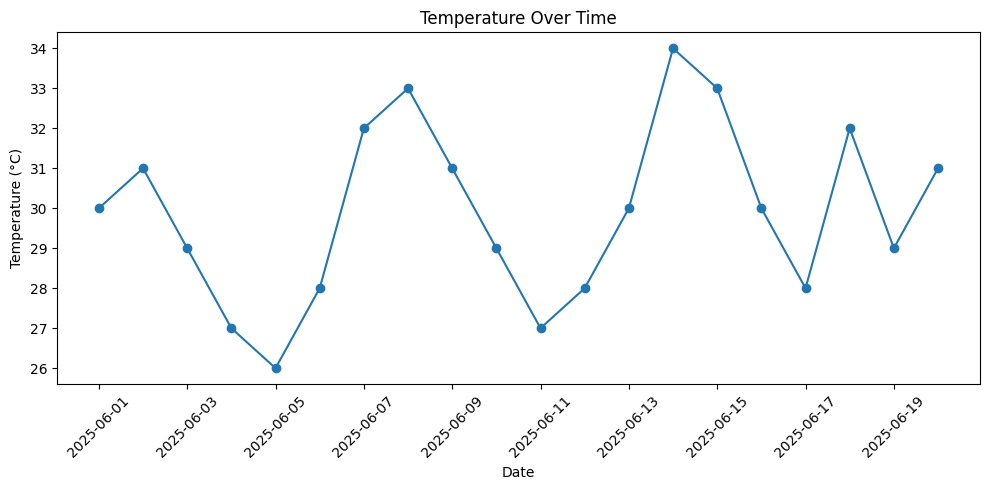

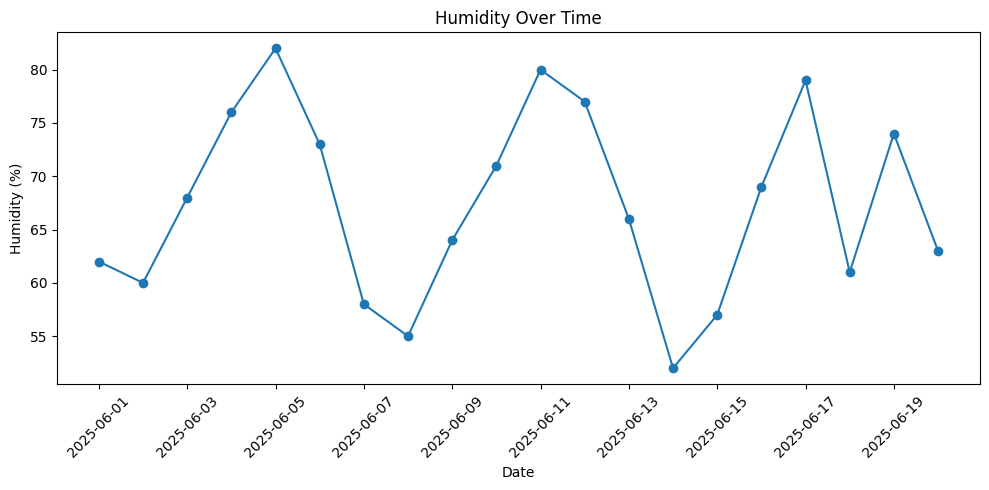

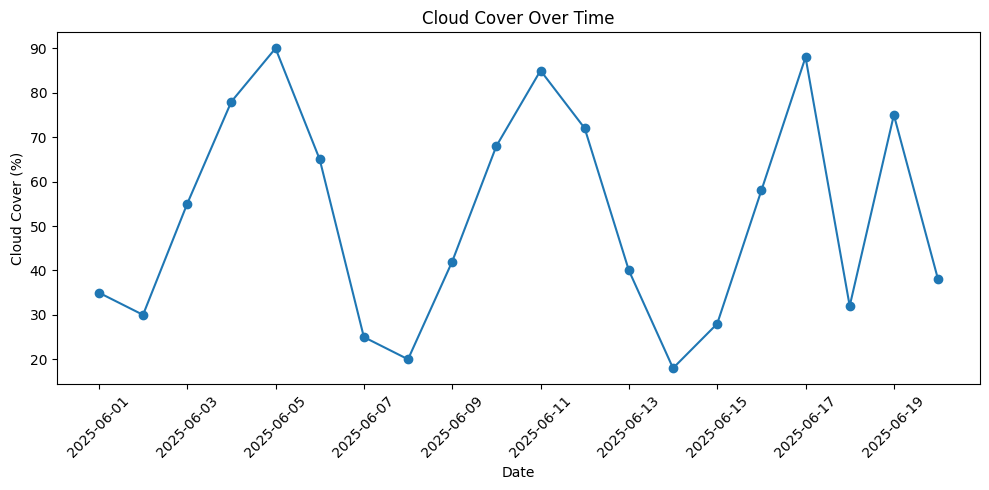


Actual Values:
[0 0 1 0]

Predicted Values:
[0 0 0 0]

Accuracy: 0.75
Accuracy Percentage: 75.0 %

Confusion Matrix:
[[3 0]
 [1 0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.75      1.00      0.86         3
           1       0.00      0.00      0.00         1

    accuracy                           0.75         4
   macro avg       0.38      0.50      0.43         4
weighted avg       0.56      0.75      0.64         4


Prediction for new weather: RAIN


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/u

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load dataset
df = pd.read_csv("weather.csv")

# Display dataset
print("First 5 rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"] + " 2025")

# Display complete dataset
print("\nComplete Dataset:")
print(df)

# Temperature visualization
plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Temperature"], marker="o")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Temperature Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Humidity visualization
plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Humidity"], marker="o")
plt.xlabel("Date")
plt.ylabel("Humidity (%)")
plt.title("Humidity Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Cloud cover visualization
plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Cloud_Cover"], marker="o")
plt.xlabel("Date")
plt.ylabel("Cloud Cover (%)")
plt.title("Cloud Cover Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Features and target
X = df[[
    "Temperature",
    "Humidity",
    "Pressure",
    "Wind_Speed",
    "Cloud_Cover"
]]

y = df["Rain_Tomorrow"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create Logistic Regression model
model = LogisticRegression()

# Train model
model.fit(X_train, y_train)

# Prediction
prediction = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, prediction)

print("\nActual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(prediction)

print("\nAccuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

# Confusion Matrix
cm = confusion_matrix(y_test, prediction)

print("\nConfusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, prediction))

# Predict new weather condition
new_weather = [[
    28,     # Temperature
    78,     # Humidity
    1006,   # Pressure
    19,     # Wind Speed
    85      # Cloud Cover
]]

new_prediction = model.predict(new_weather)

if new_prediction[0] == 1:
    print("\nPrediction for new weather: RAIN")
else:
    print("\nPrediction for new weather: NO RAIN")